In [1]:
# Cell 1: Import necessary libraries and environment setup
import os
import torch
import torchaudio
import pandas as pd
import numpy as np
import gc
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import AutoProcessor, Wav2Vec2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, accuracy_score

# Configure device and check GPU specifications
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("-" * 50)
print(f"🚀 Execution Device: {device}")

if torch.cuda.is_available():
    # Let's flex the hardware for your teammates!
    gpu_name = torch.cuda.get_device_name(0)
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / (1024**3) # Convert to GB
    print(f"🔥 Hardware Model: {gpu_name}")
    print(f"📟 Dedicated VRAM: {gpu_memory:.2f} GB")
    print(f"✨ CUDA Capability: {torch.cuda.get_device_capability(0)}")
else:
    print("⚠️ Warning: Running on CPU. Performance might be limited.")
print("-" * 50)

# Global setting: Optimization for large-scale audio processing
# Note: We are using librosa for loading to bypass torchaudio/torchcodec version conflicts
import librosa 
print("✅ Environment initialized. Ready for FinQuest 2026.")

/home/jesse/Projects/MyEnvs/finquest_2026/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--------------------------------------------------
🚀 Execution Device: cuda
🔥 Hardware Model: NVIDIA GeForce RTX 5080
📟 Dedicated VRAM: 15.46 GB
✨ CUDA Capability: (12, 0)
--------------------------------------------------
✅ Environment initialized. Ready for FinQuest 2026.


In [ ]:
# Cell 2: Load Master Protocol and perform stratified splitting
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load Master Protocol
protocol_path = "./protocol/master_protocol.csv"
df = pd.read_csv(protocol_path)

# 🚀 Core Improvement: Stratified Sampling Strategy
# We must ensure that both the Real/Fake ratio AND the "source" distribution 
# remain consistent across all three splits (Train/Dev/Test).
# This guarantees that the "difficulty" and "scenario distribution" are perfectly matched.

# First split: 80% Training, 20% Temp (for Dev & Test)
# Using 'source' as the stratification key to maintain data origin ratios.
train_df, temp_df = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df['source'], 
    random_state=42
)

# Second split: Divide Temp into Dev (10%) and Test (10%)
dev_df, test_df = train_test_split(
    temp_df, 
    test_size=0.5, 
    stratify=temp_df['source'], 
    random_state=42
)

# --- 📊 Validation Report (Confirming Stratification Success) ---
def get_source_distribution(data_df, name):
    dist = data_df['source'].value_counts(normalize=True).head(5) * 100
    return dist

print("-" * 60)
print(f"📊 DATASET SPLIT SUMMARY (Ratio: 80/10/10)")
print("-" * 60)
print(f"Total Samples  : {len(df)}")
print(f"Training Set   : {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation Set : {len(dev_df)} ({len(dev_df)/len(df):.1%})")
print(f"Testing Set    : {len(test_df)} ({len(test_df)/len(df):.1%})")
print("-" * 60)

# Displaying Top 5 sources across all sets to verify distribution consistency
print("🎯 Source Distribution Consistency Check (Top 5 sources %):")
dist_report = pd.DataFrame({
    "Full_Set": df['source'].value_counts(normalize=True).head(5) * 100,
    "Train_Set": train_df['source'].value_counts(normalize=True).head(5) * 100,
    "Dev_Set": dev_df['source'].value_counts(normalize=True).head(5) * 100,
    "Test_Set": test_df['source'].value_counts(normalize=True).head(5) * 100
})
print(dist_report.round(2))

print("-" * 60)
print("✅ Label Balance Check (Real Label 1 Ratio):")
print(f"Train: {train_df['label'].mean():.2%} | Dev: {dev_df['label'].mean():.2%} | Test: {test_df['label'].mean():.2%}")
print("-" * 60)

------------------------------------------------------------
📊 DATASET SPLIT SUMMARY (Ratio: 80/10/10)
------------------------------------------------------------
Total Samples  : 116390
Training Set   : 93112 (80.0%)
Validation Set : 11639 (10.0%)
Testing Set    : 11639 (10.0%)
------------------------------------------------------------
🎯 Source Distribution Consistency Check (Top 5 sources %):
                    Full_Set  Train_Set  Dev_Set  Test_Set
source                                                    
FOR_for-2seconds       12.89      12.89    12.89     12.89
FOR_for-norm           10.31      10.31    10.31     10.31
FOR_for-rerecorded     10.70      10.70    10.70     10.70
JSUT                   12.89      12.89    12.89     12.89
Wild                   10.31      10.31    10.31     10.31
------------------------------------------------------------
✅ Label Balance Check (Real Label 1 Ratio):
Train: 42.13% | Dev: 41.79% | Test: 42.26%
--------------------------------------

In [ ]:
# Cell 3: Forensic-Grade Augmented Dataset (Numerical Stability Version)
import librosa
import torch
import numpy as np
import random
import os
from torch.utils.data import Dataset
from audiomentations import Compose, AddGaussianNoise, Shift, Gain, RoomSimulator, Mp3Compression, TimeMask

class FinQuestDataset(Dataset):
    """
    Advanced Dataset: Supports Asymmetric Augmentation, Cyclic Tiling (Repeating), 
    and Dynamic Attention Masking.
    """
    def __init__(self, dataframe, processor, max_length=64000, augment=False):
        self.df = dataframe
        self.processor = processor
        self.max_length = max_length
        self.augment = augment
        
        # 🛡️ Pure Source Keywords: High-fidelity or laboratory-grade audio sources
        # These need heavy augmentation to simulate real-world degradation.
        self.pure_clean_keywords = ['Real', 'LJ', 'JSUT', 'ASV', 'WF', 'norm', 'original']
        
        if self.augment:
            # High-intensity augmentation pipeline for "clean" sources
            self.augmenter = Compose([
                Gain(min_gain_db=-6, max_gain_db=3, p=0.5),
                RoomSimulator(p=0.15), # 略微提高，模拟真实的翻录环境
                Mp3Compression(min_bitrate=32, max_bitrate=128, p=0.3),
                TimeMask(min_band_part=0.05, max_band_part=0.1, fade_duration=0.005, p=0.3),
                AddGaussianNoise(min_amplitude=0.001, max_amplitude=0.005, p=0.2),
                Shift(min_shift=-0.5, max_shift=0.5, p=0.5),
            ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = row['path']
        label = row['label']
        source = row['source']

        try:
            if not os.path.exists(path):
                raise FileNotFoundError

            # 1. Load Audio (Fixed at 16kHz Mono)
            waveform, _ = librosa.load(path, sr=16000, mono=True)
            waveform = np.nan_to_num(waveform)
            
            # 2. 🧠 Asymmetric Augmentation Logic
            if self.augment:
                # Check if the source belongs to the "Pure" category
                is_pure = any(k in source for k in self.pure_clean_keywords)
                
                if is_pure:
                    # Apply heavy transformations to lab-grade data
                    waveform = self.augmenter(samples=waveform.astype(np.float32), sample_rate=16000)
                else:
                    # Dirty Sources (rerecorded, Wild): Apply only minor gain jitter 
                    # to preserve their natural "in-the-wild" artifacts.
                    if random.random() < 0.5:
                        waveform = waveform * random.uniform(0.9, 1.1)
                
                waveform = np.nan_to_num(waveform)

            # 3. 🚀 Cyclic Tiling (Tile) Strategy
            num_samples = len(waveform)
            attention_mask = torch.ones(self.max_length, dtype=torch.long)

            if num_samples >= self.max_length:
                if self.augment:
                    start = random.randint(0, num_samples - self.max_length)
                else:
                    start = (num_samples - self.max_length) // 2
                waveform = waveform[start : start + self.max_length]
            else:
                # ⚡ Short audio: Cyclic Tiling (Repeat audio to fill the 4s window)
                # This ensures every frame in the 4s window provides feature feedback.
                repeats = (self.max_length // num_samples) + 1
                waveform = np.tile(waveform, repeats)[:self.max_length]
                # 注意：即便 Tile 了，attention_mask 依然设为 1 是正确的，
                # 因为我们要让模型在 4s 内每一帧都有特征反馈。

            # 4. Feature Extraction (Explicitly disabling internal padding/truncation)
            # We handle signal length manually via the Tiling strategy above.
            waveform_t = torch.from_numpy(waveform.copy())
            inputs = self.processor(
                waveform_t, 
                sampling_rate=16000, 
                return_tensors="pt",
                padding=False,     # 🚀 手动控制了
                truncation=False   # 🚀 手动控制了
            )
            input_values = inputs.input_values.squeeze(0)

            # 5. 🛡️ Numerical Stability Safety Check
            if torch.isnan(input_values).any() or torch.isinf(input_values).any():
                return self.__getitem__((idx + 1) % len(self.df))
            
            input_values = torch.clamp(input_values, -10.0, 10.0)

            return {
                "input_values": input_values,
                "attention_mask": attention_mask,
                "label": torch.tensor(label, dtype=torch.long)
            }
            
        except Exception as e:
            return self.__getitem__((idx + random.randint(1, 100)) % len(self.df))

print("✅ Cell 3: Refined Asymmetric Dataset ready for Cell 6.")

✅ Cell 3: Refined Asymmetric Dataset ready for Cell 6.


In [ ]:
# Cell 4: Model Architecture Definition (Wav2Vec2 + Multi-Scale Attentive Pooling)
import torch.nn as nn
from transformers import AutoProcessor, Wav2Vec2Model

class MultiScaleAttentivePooling(torch.nn.Module):
    """
    Evolved Pooling Layer: Aggregates temporal importance (Mean) while capturing 
    feature volatility (Standard Deviation).
    This is highly effective for detecting micro-acoustic "stiffness" or "unnatural smoothness" 
    inherent in AI-synthesized speech.
    """
    def __init__(self, hidden_size):
        super().__init__()
        self.attention = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 128),
            torch.nn.Tanh(),
            torch.nn.Linear(128, 1)
        )

    def forward(self, x):
        # Input x shape: [batch, seq_len, 768]
        # 1. Calculate Attention Weights: Significance of each temporal frame
        attn_weights = torch.softmax(self.attention(x), dim=1) # [batch, seq_len, 1]
        
        # 2. Calculate Weighted Mean (mu)
        mu = torch.sum(attn_weights * x, dim=1) # [batch, 768]
        
        # 3. Calculate Weighted Standard Deviation (sigma)
        # Formula: sqrt( sum( weights * (x - mu)^2 ) )
        # We unsqueeze mu back to sequence length for element-wise subtraction
        delta = x - mu.unsqueeze(1) # [batch, seq_len, 768]
        var = torch.sum(attn_weights * (delta ** 2), dim=1)

        # std = torch.sqrt(var + 1e-6) # 加个微小值防止梯度爆炸 [batch, 768]
        
        std = torch.sqrt(torch.clamp(var, min=1e-9)) # 更稳健的标准差计算，避免数值问题

        # 5. Concatenate Mean and Std: Feature dimension expands from 768 to 1536
        return torch.cat([mu, std], dim=-1)

# Step 1: Load the Wav2Vec 2.0 Base Engine
# Note: Ensure the 'device' variable was defined in a previous cell
processor = AutoProcessor.from_pretrained("facebook/wav2vec2-base")
backbone = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base").to(device)

# Step 2: Initialize Multi-Scale Attentive Pooling Layer
pooling = MultiScaleAttentivePooling(768).to(device)

# Step 3: Define Classification Head (MLP)
# 🚀 Key Modification: Input dimension upgraded from 768 to 1536
classifier = torch.nn.Sequential(
    torch.nn.Linear(1536, 512), # Doubled input, expanded hidden layer for richer capacity
    torch.nn.ReLU(),
    torch.nn.BatchNorm1d(512),   # Batch Normalization for training stability
    torch.nn.Dropout(0.3),      # Dropout to prevent overfitting
    torch.nn.Linear(512, 256),
    torch.nn.ReLU(),
    torch.nn.Linear(256, 2)      # # Final output logits: [Fake, Real]
).to(device)

print(f"✅ Model architecture evolved to MULTI-SCALE on {device}.")
print(f"🔹 Aggregation: Mean + Std Deviation (Concat Dimension: 1536)")
print(f"🔹 Strategy: Capturing acoustic 'texture' for deepfake detection.")

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 58292.59it/s]
Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model architecture evolved to MULTI-SCALE on cuda.
🔹 Aggregation: Mean + Std Deviation (Concat Dimension: 1536)
🔹 Strategy: Capturing acoustic 'texture' for deepfake detection.


In [ ]:
# Cell 5: Advanced Hyperparameters & Dynamic Scheduler (Forensic Edition)
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau

# 1. 🚀 Initialize Datasets (Ensure Cell 3 logic has been executed)
# We explicitly pass the processor here to ensure feature extraction consistency.
train_dataset = FinQuestDataset(train_df, processor, augment=True)
dev_dataset   = FinQuestDataset(dev_df, processor, augment=False)

# 2. 🚀 DataLoaders (Optimized for High-Performance Compute)
# Batch_size=32 provides a stable balance between GPU memory and gradient variance.
train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True,
    drop_last=True  # Drops the last incomplete batch to prevent gradient spikes
)
dev_loader = DataLoader(
    dev_dataset, 
    batch_size=32, 
    num_workers=4, 
    pin_memory=True
)

# 3. 🚀 Layer-wise Learning Rate Decay (LLRD) + Optimizer
# We manage learning rates differentially to protect pre-trained weights.
optimizer = torch.optim.AdamW([
    # A. Freeze CNN Feature Extractor: These features are universal; do not fine-tune.
    {"params": backbone.feature_extractor.parameters(), "lr": 0}, 
    
    # B. Transformer Encoder: Ultra-low learning rate for subtle adaptation only.
    {"params": backbone.encoder.parameters(), "lr": 4e-6}, 
    
    # C. Task-Specific Layers (Pooling & Classifier): The primary training zone.
    {"params": pooling.parameters(), "lr": 4e-5},
    {"params": classifier.parameters(), "lr": 4e-5},
], weight_decay=0.01) # Robust regularization coefficient

# 4. 🚀 Loss Function: Cross-Entropy
# We rely on LLRD and heavy Augmentation to prevent overfitting.
criterion = torch.nn.CrossEntropyLoss()

# 5. 🚀 Dynamic Scheduler (ReduceLROnPlateau)
# Monitoring Validation EER/Loss to adaptively throttle the learning rate.
SCHEDULER_PATIENCE = 2  
SCHEDULER_FACTOR = 0.5  

scheduler = ReduceLROnPlateau(
    optimizer, 
    mode='min',        
    factor=SCHEDULER_FACTOR, 
    patience=SCHEDULER_PATIENCE, 
    min_lr=1e-7,       
    # verbose=True       # Doesn't work......
)

# 6. 🚀 Early Stopping Mechanism
# Allows the model sufficient time to digest high-intensity augmented data.
EARLY_STOP_PATIENCE = 5 # 如果连续 5 次验证指标不降，则停止训练

# 7. Training Summary Report
print("-" * 60)
print("🚀 FINQUEST 2026: HYPERPARAMETER CONFIG (STABLE VERSION)")
print("-" * 60)
print(f"🔹 Encoder LR      : 4e-6 (LLRD Active)")
print(f"🔹 Top Layers LR   : 4e-5")
print(f"🔹 Batch Size      : 32 (Drop Last: True)")
print(f"🔹 Scheduler       : Plateau (Patience: {SCHEDULER_PATIENCE}, Factor: {SCHEDULER_FACTOR})")
print(f"🔹 Early Stopping  : {EARLY_STOP_PATIENCE} Epochs")
print("-" * 60)
print("✅ Hyperparameters locked. Ready for high-fidelity training.")

------------------------------------------------------------
🚀 FINQUEST 2026: HYPERPARAMETER CONFIG (STABLE VERSION)
------------------------------------------------------------
🔹 Encoder LR      : 4e-6 (LLRD Active)
🔹 Top Layers LR   : 4e-5
🔹 Batch Size      : 32 (Drop Last: True)
🔹 Scheduler       : Plateau (Patience: 2, Factor: 0.5)
🔹 Early Stopping  : 5 Epochs
------------------------------------------------------------
✅ Hyperparameters locked. Ready for high-fidelity training.


In [ ]:
# Cell 6: Training & Validation Loop (Dynamic LLRD + Plateau Optimized)
import os
import warnings
import logging
import torch
import numpy as np
import csv
from tqdm import tqdm
from sklearn.metrics import roc_curve, accuracy_score

# ==============================================================================
# 🚀 1. Environment Setup & Directory Initialization
# ==============================================================================
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore") 
MODEL_DIR = "./model"
LOG_FILE = os.path.join(MODEL_DIR, "training_log.csv")
os.makedirs(MODEL_DIR, exist_ok=True)

# Initialize CSV Log for experiment tracking
if not os.path.exists(LOG_FILE):
    with open(LOG_FILE, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(["epoch", "train_loss", "dev_acc", "dev_eer", "is_best"])

def save_metrics_to_csv(epoch, loss, acc, eer, is_best):
    with open(LOG_FILE, 'a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([epoch, f"{loss:.6f}", f"{acc:.4f}", f"{eer:.4f}", "YES" if is_best else "NO"])

# ==============================================================================
# 🚀 2. Evaluation Function (Attention Mask Support)
# ==============================================================================
def evaluate(model_base, pool_layer, clf_layer, loader):
    model_base.eval()
    pool_layer.eval()
    clf_layer.eval()
    all_scores, all_labels = [], []
    
    with torch.no_grad():
        for batch in tqdm(loader, desc="Validating", leave=False):
            # Extract data and move to device
            inputs = batch["input_values"].to(device)
            masks = batch["attention_mask"].to(device) # 必须传递 Mask
            labels = batch["label"].to(device)
            
            # Inference Pipeline
            outputs = model_base(inputs, attention_mask=masks).last_hidden_state
            pooled = pool_layer(outputs)
            logits = clf_layer(pooled)
            
            # Calculate probabilities for the "Real" class (index 1)
            probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            all_scores.extend(probs)
            all_labels.extend(labels.cpu().numpy())
            
    all_labels = np.array(all_labels)
    all_scores = np.array(all_scores)
    
    # Metrics Calculation: EER and Accuracy
    fpr, tpr, _ = roc_curve(all_labels, all_scores, pos_label=1)
    fnr = 1 - tpr
    eer = fpr[np.nanargmin(np.abs(fnr - fpr))]
    acc = accuracy_score(all_labels, all_scores > 0.5)
    return acc, eer

# --- Training Configurations ---
max_epochs = 30 
counter = 0        
patience = EARLY_STOP_PATIENCE 

# ==============================================================================
# 🚀 3. Weight Warm Start (with Auto-Calibration Logic)
# ==============================================================================
checkpoint_path = os.path.join(MODEL_DIR, "best_deepfake_model.pth")
best_eer = 1.0 # Default worst-case EER

if os.path.exists(checkpoint_path):
    print(f"📦 Found existing checkpoint: {checkpoint_path}")
    print(f"🔥 Loading weights for Warm Start...")
    try:
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
        backbone.load_state_dict(checkpoint['backbone'])
        pooling.load_state_dict(checkpoint['pooling'])
        classifier.load_state_dict(checkpoint['classifier'])
        
        # 🚀 Core Improvement: Auto-test current model to align best_eer
        print("🔍 Calibrating baseline EER from loaded weights...")
        _, best_eer = evaluate(backbone, pooling, classifier, dev_loader)
        print(f"✅ Baseline EER aligned to: {best_eer:.4f}. Optimization will continue from here.")
    except Exception as e:
        print(f"⚠️ Error loading checkpoint: {e}. Starting from scratch.")
else:
    print("🆕 No checkpoint found. Initializing new training session.")

# ==============================================================================
# 🚀 4. Main Training Loop
# ==============================================================================
print(f"🏁 FinQuest 2026: Training initiated. Device: {device}")

for epoch in range(max_epochs):
    backbone.train()
    pooling.train()
    classifier.train()
    total_loss = 0
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}")
    for batch in pbar:
        optimizer.zero_grad()
        
        # 1. Extract batch data
        inputs = batch["input_values"].to(device)
        masks = batch["attention_mask"].to(device) # 🚀 这里的 Mask 告诉 Wav2Vec2 哪里是循环填充的
        labels = batch["label"].to(device)
        
        # 2. Forward Pass
        outputs = backbone(inputs, attention_mask=masks).last_hidden_state
        pooled = pooling(outputs)
        logits = classifier(pooled)
        
        # 3. Loss Calculation & Backpropagation
        loss = criterion(logits, labels)
        loss.backward()

        # 4. Gradient Clipping (Prevents explosion under heavy augmentation)
        all_params = list(backbone.parameters()) + list(pooling.parameters()) + list(classifier.parameters())
        torch.nn.utils.clip_grad_norm_(all_params, max_norm=0.5)
        
        optimizer.step()
        total_loss += loss.item()
        
        # 5. Monitor Learning Rate
        current_lr = optimizer.param_groups[-1]['lr']
        pbar.set_postfix(loss=f"{loss.item():.4f}", lr=f"{current_lr:.2e}")

    # --- Validation Phase ---
    dev_acc, dev_eer = evaluate(backbone, pooling, classifier, dev_loader)
    avg_loss = total_loss / len(train_loader)
    
    # Adjust LR based on EER plateau
    scheduler.step(dev_eer) 
    
    is_best = dev_eer < best_eer
    save_metrics_to_csv(epoch, avg_loss, dev_acc, dev_eer, is_best)
    
    print(f"\n📊 [Epoch {epoch} Summary]")
    print(f"   - Training Loss : {avg_loss:.6f}")
    print(f"   - Dev Accuracy  : {dev_acc:.4f}")
    print(f"   - Dev EER       : {dev_eer:.4f}")
    print(f"   - Current LR    : {optimizer.param_groups[-1]['lr']:.2e}")
    
    if is_best:
        best_eer = dev_eer
        counter = 0  
        save_path = os.path.join(MODEL_DIR, "best_deepfake_model.pth")
        
        # Save a clean state dict for deployment
        clean_state_dict = {
            'backbone': backbone.state_dict(),
            'pooling': pooling.state_dict(),
            'classifier': classifier.state_dict()
        }
        
        torch.save(clean_state_dict, save_path)
        print(f"🥇 New Best Model! Weights updated in {save_path}")
    else:
        counter += 1
        print(f"⏱ No improvement. Counter: {counter}/{patience}")
    
    if counter >= patience:
        print(f"🛑 Early Stopping triggered. Final Best EER: {best_eer:.4f}")
        break
    print("-" * 50)

print("\n✨ Training session complete. Ready for forensic analysis.")

🆕 No checkpoint found. Initializing new training session.
🏁 FinQuest 2026: Training initiated. Device: cuda


Epoch 0: 100%|██████████| 2909/2909 [16:03<00:00,  3.02it/s, loss=0.1801, lr=4.00e-05]



📊 [Epoch 0 Summary]
   - Training Loss : 0.152931
   - Dev Accuracy  : 0.9924
   - Dev EER       : 0.0072
   - Current LR    : 4.00e-05
🥇 New Best Model! Weights updated in ./model/best_deepfake_model.pth
--------------------------------------------------


Epoch 1: 100%|██████████| 2909/2909 [15:56<00:00,  3.04it/s, loss=0.0749, lr=4.00e-05]



📊 [Epoch 1 Summary]
   - Training Loss : 0.076402
   - Dev Accuracy  : 0.9940
   - Dev EER       : 0.0053
   - Current LR    : 4.00e-05
🥇 New Best Model! Weights updated in ./model/best_deepfake_model.pth
--------------------------------------------------


Epoch 2: 100%|██████████| 2909/2909 [16:16<00:00,  2.98it/s, loss=0.0666, lr=4.00e-05]


... (21 outputs left out)

Epoch 13: 100%|██████████| 2909/2909 [15:42<00:00,  3.09it/s, loss=0.0000, lr=1.00e-05]



📊 [Epoch 13 Summary]
   - Training Loss : 0.019293
   - Dev Accuracy  : 0.9978
   - Dev EER       : 0.0018
   - Current LR    : 1.00e-05
⏱ No improvement. Counter: 4/5
--------------------------------------------------


Epoch 14: 100%|██████████| 2909/2909 [15:43<00:00,  3.08it/s, loss=0.0000, lr=1.00e-05]
                                                             


📊 [Epoch 14 Summary]
   - Training Loss : 0.018217
   - Dev Accuracy  : 0.9982
   - Dev EER       : 0.0013
   - Current LR    : 1.00e-05
⏱ No improvement. Counter: 5/5
🛑 Early Stopping triggered. Final Best EER: 0.0013

✨ Training session complete. Ready for forensic analysis.


In [ ]:
# Cell 7: Full Test Evaluation and Model Source Attribution Report
import librosa
import torch
import pandas as pd
import numpy as np
import os
import csv
from tqdm import tqdm
from sklearn.metrics import roc_curve, accuracy_score, roc_auc_score

# 1. 🔄 Load Optimized Weights
print("🔄 Loading Multi-Scale optimized weights for final evaluation...")
checkpoint = torch.load("model/best_deepfake_model.pth", weights_only=False, map_location=device)
backbone.load_state_dict(checkpoint['backbone'])
pooling.load_state_dict(checkpoint['pooling'])
classifier.load_state_dict(checkpoint['classifier'])

backbone.eval()
pooling.eval()
classifier.eval()

# 2. 📝 Configure CSV Export Path
RESULT_CSV = "model/inference_detailed_results.csv"
all_data_for_csv = []

def sliding_window_inference(path, window_sec=4.0, stride_sec=2.0):
    """
    Sliding-window inference logic for variable-length audio.
    Ensures long audio is fully analyzed and short audio is properly tiled.
    """
    # Load audio (Full duration)
    wav, _ = librosa.load(path, sr=16000, mono=True)
    num_samples = len(wav)
    window_size = int(window_sec * 16000)
    stride_size = int(stride_sec * 16000)
    
    windows = []
    # Case A: Audio shorter than 4s -> Use Tiling (Aligns with training logic)
    if num_samples < window_size:
        repeats = (window_size // num_samples) + 1
        wav_tile = np.tile(wav, repeats)[:window_size]
        windows.append(wav_tile)
    # Case B: Audio longer than 4s -> Slice into sliding windows
    else:
        for start in range(0, num_samples - window_size + 1, stride_size):
            windows.append(wav[start : start + window_size])
        # Capture the final window at the end of the file
        if (num_samples - window_size) % stride_size != 0:
            windows.append(wav[-window_size:])

    # Perform batch inference across all windows
    scores = []
    with torch.no_grad():
        for w in windows:
            inputs = processor(w, sampling_rate=16000, return_tensors="pt").input_values.to(device)
            # 这里的 attention_mask 为全 1
            mask = torch.ones(inputs.shape, dtype=torch.long).to(device)
            hidden_states = backbone(inputs, attention_mask=mask).last_hidden_state
            pooled = pooling(hidden_states)
            logits = classifier(pooled)
            prob = torch.softmax(logits, dim=1)[0, 1].item() # Real 概率
            scores.append(prob)
            
    return scores

# --- 3. Initiate Large-Scale Inference ---
all_labels = []
all_final_scores = []
source_stats = {}

print(f"🔍 Running Sliding-Window Inference on {len(test_df)} samples...")

for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Inference Phase"):
    try:
        path, label, source = row['path'], row['label'], row['model_name']
        
        # Execute sliding window to get multiple scores per file
        window_scores = sliding_window_inference(path)
        
        # Decision Fusion: Mean score used for final determination
        # Note: For higher sensitivity, one might use np.min() (if any segment is fake, overall is fake)
        final_score = np.mean(window_scores)
        
        all_final_scores.append(final_score)
        all_labels.append(label)
        
        # Log detailed data for CSV export
        all_data_for_csv.append({
            "path": path,
            "label": label,
            "source": source,
            "final_score": f"{final_score:.4f}",
            "window_scores": [f"{s:.4f}" for s in window_scores],
            "num_windows": len(window_scores),
            "prediction": 1 if final_score > 0.5 else 0
        })
        
        # Aggregate performance stats per source/model
        if source not in source_stats:
            source_stats[source] = {"total": 0, "correct": 0}
        source_stats[source]["total"] += 1
        if (1 if final_score > 0.5 else 0) == label:
            source_stats[source]["correct"] += 1
            
    except Exception as e:
        print(f"❌ Error at {path}: {e}")

# --- 4. Export Detailed Results to CSV ---
df_results = pd.DataFrame(all_data_for_csv)
df_results.to_csv(RESULT_CSV, index=False)
print(f"\n✅ Detailed results exported to: {RESULT_CSV}")

# --- 5. Metrics Calculation & Final Report ---
all_labels = np.array(all_labels)
all_final_scores = np.array(all_final_scores)

final_acc = accuracy_score(all_labels, all_final_scores > 0.5)
fpr, tpr, _ = roc_curve(all_labels, all_final_scores, pos_label=1)
eer = fpr[np.nanargmin(np.abs(1 - tpr - fpr))]
auc = roc_auc_score(all_labels, all_final_scores)

print("\n" + "="*60)
print("🚀 FINQUEST 2026: SLIDING-WINDOW PERFORMANCE REPORT")
print("="*60)
print(f"{'Overall Accuracy':<20} : {final_acc:.2%}")
print(f"{'Equal Error Rate':<20} : {eer:.4f}")
print(f"{'Area Under Curve':<20} : {auc:.4f}")
print("-" * 60)
print(f"{'Source':<25} | {'Count':<8} | {'Accuracy':<10}")
print("-" * 60)
for src, res in source_stats.items():
    acc = res['correct'] / res['total']
    print(f"{src:<25} | {res['total']:<8} | {acc:.2%}")
print("-" * 60)

torch.cuda.empty_cache()
print("✨ RTX 5080 evaluation mission accomplished.")

🔄 Loading Multi-Scale optimized weights for final evaluation...
🔍 Running Sliding-Window Inference on 11639 samples...


Inference Phase: 100%|██████████| 11639/11639 [02:26<00:00, 79.39it/s] 


✅ Detailed results exported to: model/inference_detailed_results.csv

🚀 FINQUEST 2026: SLIDING-WINDOW PERFORMANCE REPORT
Overall Accuracy     : 99.91%
Equal Error Rate     : 0.0007
Area Under Curve     : 1.0000
------------------------------------------------------------
Source                    | Count    | Accuracy  
------------------------------------------------------------
for-2seconds              | 1500     | 100.00%
for-rerecorded            | 1245     | 99.92%
melgan/pwg                | 997      | 99.90%
melgan                    | 426      | 99.53%
for-norm                  | 1200     | 100.00%
wild                      | 1200     | 99.75%
original                  | 1503     | 100.00%
fastspeech2_pwg           | 1000     | 100.00%
for-original              | 1144     | 100.00%
A02                       | 116      | 100.00%
waveglow                  | 148      | 100.00%
A03                       | 108      | 100.00%
A01                       | 117      | 100.00%
-        

In [ ]:
# Cell 8: Multi-Scenario Stress Test (Sliding-Window & Tile Aligned)
import os
import torch
import torch.nn as nn
import librosa
import numpy as np
import pandas as pd
from tqdm import tqdm
from pathlib import Path
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor

# ==============================================================================
# 1. Environment & Configuration
# ==============================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TARGET_SR = 16000
MAX_LENGTH = 64000  # 4秒音频标准
WINDOW_SEC = 4.0
STRIDE_SEC = 2.0

BASE_PATH = Path("/home/jesse/Projects/MyProjects/2026_FinQuest/Finquest_Wav2Vec_Deepfake/Fake_or_Real")
MODEL_PATH = "model/best_deepfake_model.pth"
MODEL_NAME = "facebook/wav2vec2-base"

# ==============================================================================
# 2. Model Architecture (🚀 Strictly Aligned with Evolved Version in Cell 4)
# ==============================================================================
class MultiScaleAttentivePooling(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        attn_weights = torch.softmax(self.attention(x), dim=1)
        mu = torch.sum(attn_weights * x, dim=1)
        var = torch.sum(attn_weights * (x - mu.unsqueeze(1))**2, dim=1)
        std = torch.sqrt(var + 1e-6)
        return torch.cat([mu, std], dim=-1)

class FinQuestDeepfakeModel(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.wav2vec2 = Wav2Vec2Model.from_pretrained(model_name)
        self.pooling = MultiScaleAttentivePooling(768)
        self.classifier = nn.Sequential(
            nn.Linear(1536, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 2)
        )
    def forward(self, input_values):
        # Forward pass through backbone, pooling, and classification head
        outputs = self.wav2vec2(input_values).last_hidden_state
        pooled = self.pooling(outputs) 
        return self.classifier(pooled)

# ==============================================================================
# 3. Loading Weights
# ==============================================================================
processor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_NAME)
model = FinQuestDeepfakeModel(MODEL_NAME)
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)

# Map dictionary keys from the training checkpoint to the model layers
model.wav2vec2.load_state_dict(checkpoint["backbone"])
model.pooling.load_state_dict(checkpoint["pooling"])
model.classifier.load_state_dict(checkpoint["classifier"])

model.to(DEVICE)
model.eval()
print("✅ Multi-Scale Architecture ALIGNED. Sliding-Window Engine Ready.")

# ==============================================================================
# 4. Adaptive Sliding-Window Inference (🚀 Core Alignment Logic)
# ==============================================================================
def predict_scenario_audio(audio_path, model, processor, device):
    """
    Adaptive inference: Uses Tiling for short audio and Sliding-Window for long audio.
    """
    try:
        wav, _ = librosa.load(audio_path, sr=TARGET_SR, mono=True)
        num_samples = len(wav)
        win_size = int(WINDOW_SEC * TARGET_SR)
        
        # --- Strategy A: Short Audio (e.g., 2-second scenario) -> Cyclic Tiling ---
        if num_samples < win_size:
            repeats = (win_size // num_samples) + 1
            wav_input = np.tile(wav, repeats)[:win_size]
            windows = [wav_input]
        # --- Strategy B: Long Audio -> Sliding-Window Slicing ---
        else:
            stride_size = int(STRIDE_SEC * TARGET_SR)
            windows = [wav[i : i + win_size] for i in range(0, num_samples - win_size + 1, stride_size)]
            if not windows: windows = [wav[:win_size]] # 保底

        # Execute inference and aggregate results via Mean Fusion
        scores = []
        with torch.no_grad():
            for w in windows:
                inputs = processor(w, sampling_rate=TARGET_SR, return_tensors="pt").input_values.to(device)
                logits = model(inputs)
                prob = torch.softmax(logits, dim=-1)[0, 1].item() # Real 概率
                scores.append(prob)
        
        return np.mean(scores)
    except Exception as e:
        return 0.5

# ==============================================================================
# 5. Multi-Scenario Execution (Stratified Scenario Evaluation)
# ==============================================================================
SCENARIOS = ["for-2seconds", "for-norm", "for-original", "for-rerecorded"]
summary_report = {}
analysis_buffer = []

print(f"\n🔍 Starting Forensic Stress Test on {len(SCENARIOS)} scenarios...")

for scenario in SCENARIOS:
    # Adjust path structure based on local directory layout
    test_path = BASE_PATH / scenario / "testing"
    if not test_path.exists(): 
        print(f"⚠️ Scenario path not found: {test_path}")
        continue
        
    print(f"\n▶️ Testing Scenario: [{scenario}]")
    scenario_correct, scenario_total = 0, 0
    
    for label_str in ["real", "fake"]:
        folder = test_path / label_str
        if not folder.exists(): continue
        
        true_label = 1 if label_str == "real" else 0
        files = list(folder.glob("*.wav"))
        
        for f in tqdm(files, desc=f"  {label_str}", leave=False):
            # Perform adaptive inference
            score = predict_scenario_audio(f, model, processor, DEVICE)
            pred_label = 1 if score > 0.5 else 0
            
            if pred_label == true_label: scenario_correct += 1
            scenario_total += 1

            # Log misclassifications or "uncertain" predictions (0.45-0.55) for post-mortem analysis
            if pred_label != true_label or (0.45 < score < 0.55):
                analysis_buffer.append({
                    "Scenario": scenario,
                    "Filename": f.name,
                    "Actual": "REAL" if true_label == 1 else "FAKE",
                    "Pred": "REAL" if pred_label == 1 else "FAKE",
                    "Score": f"{score:.4f}"
                })
                    
    if scenario_total > 0:
        acc = (scenario_correct / scenario_total)
        summary_report[scenario] = acc
        print(f"✨ Result for [{scenario}]: Accuracy = {acc:.2%}")

# ==============================================================================
# 6. Final Comprehensive Report
# ==============================================================================
print("\n" + "="*60 + "\n📊 SCENARIO STRESS TEST SUMMARY\n" + "-"*60)
for scene, acc in summary_report.items():
    status = "🔥 STRONG" if acc > 0.9 else "⚠️ WEAK"
    print(f"{scene:<20} | Accuracy: {acc:.2%} | Status: {status}")
print("="*60)

if analysis_buffer:
    error_df = pd.DataFrame(analysis_buffer)
    error_df.to_csv("model/scenario_error_analysis.csv", index=False)
    print(f"🚩 Detailed Error Report saved to: model/scenario_error_analysis.csv")

Loading weights: 100%|██████████| 211/211 [00:00<00:00, 47079.38it/s]
Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Multi-Scale Architecture ALIGNED. Sliding-Window Engine Ready.

🔍 Starting Forensic Stress Test on 4 scenarios...

▶️ Testing Scenario: [for-2seconds]


✨ Result for [for-2seconds]: Accuracy = 89.06%

▶️ Testing Scenario: [for-norm]


✨ Result for [for-norm]: Accuracy = 94.28%

▶️ Testing Scenario: [for-original]


✨ Result for [for-original]: Accuracy = 91.89%

▶️ Testing Scenario: [for-rerecorded]


✨ Result for [for-rerecorded]: Accuracy = 91.05%

📊 SCENARIO STRESS TEST SUMMARY
------------------------------------------------------------
for-2seconds         | Accuracy: 89.06% | Status: ⚠️ WEAK
for-norm             | Accuracy: 94.28% | Status: 🔥 STRONG
for-original         | Accuracy: 91.89% | Status: 🔥 STRONG
for-rerecorded       | Accuracy: 91.05% | Status: 🔥 STRONG
🚩 Detailed Error Report saved to: model/scenario_error_analysis.csv


🔍 ERROR DISTRIBUTION ANALYSIS
Pred                   FAKE  REAL
Scenario       Actual            
for-2seconds   FAKE       0   119
for-norm       FAKE       1   265
for-original   FAKE       1   375
               REAL       1     0
for-rerecorded FAKE       0    68
               REAL       5     0

🚩 Blindly Confident Errors (Score > 0.9 or < 0.1): 783
📈 Total Errors in Report: 835

📝 Filename Pattern Analysis (Top 5 Keywords in Errors):
Filename
mono.wav       458
16k.wav        385
norm.wav       385
silence.wav    385
2sec.wav       119
Name: count, dtype: int64


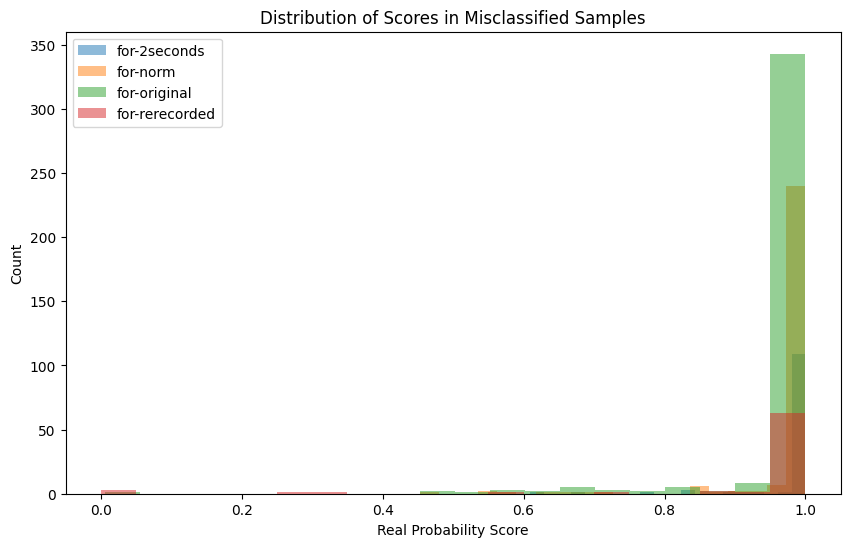

In [ ]:
# Cell 9: Visualization of Report
import pandas as pd
import matplotlib.pyplot as plt

# Load the forensic error analysis report
analysis_path = "model/scenario_error_analysis.csv"
df = pd.read_csv(analysis_path)

# 1. 🔍 Overall Error Distribution Breakdown
print("="*50)
print("🔍 ERROR DISTRIBUTION ANALYSIS")
print("="*50)
summary = df.groupby(['Scenario', 'Actual', 'Pred']).size().unstack(fill_value=0)
print(summary)

# 2. 🚩 Confidence Deviation Analysis (Detecting "Blind Confidence")
# We identify samples where the model was "extremely wrong" (e.g., Score > 0.9 for Fake)
df['Score'] = df['Score'].astype(float)
# 看看模型是“惨胜/惨败”还是“盲目自信”
extremely_confident_errors = df[((df['Actual'] == 'FAKE') & (df['Score'] > 0.9)) | 
                                ((df['Actual'] == 'REAL') & (df['Score'] < 0.1))]

print(f"\n🚩 Blindly Confident Errors (Score > 0.9 or < 0.1): {len(extremely_confident_errors)}")
print(f"📈 Total Errors in Report: {len(df)}")

# 3. 📝 Acoustic Metadata / Filename Pattern Analysis
# Identifying if specific keywords (e.g., 'silence', 'high_noise') are overrepresented in errors
print("\n📝 Filename Pattern Analysis (Top 5 Keywords in Errors):")
patterns = df['Filename'].str.split('_').explode().value_counts().head(5)
print(patterns)

# 4. 📊 Score Distribution Visualization
# Visualizing how "confused" the model was across different attack scenarios
plt.figure(figsize=(10, 6))
for scene in df['Scenario'].unique():
    subset = df[df['Scenario'] == scene]
    plt.hist(subset['Score'], bins=20, alpha=0.5, label=scene)
plt.title("Distribution of Scores in Misclassified Samples")
plt.xlabel("Real Probability Score")
plt.ylabel("Count")
plt.legend()
plt.show()